### **7. To understand various image noise models and to write programs for:**

a. Image restoration

b. Remove Salt and Pepper Noise

c. Minimize Gaussian noise

d. Median filter and Weiner filter

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, img_as_float
from skimage.util import random_noise
from scipy.ndimage import gaussian_filter, median_filter
from numpy.fft import fft2, ifft2, fftshift, ifftshift

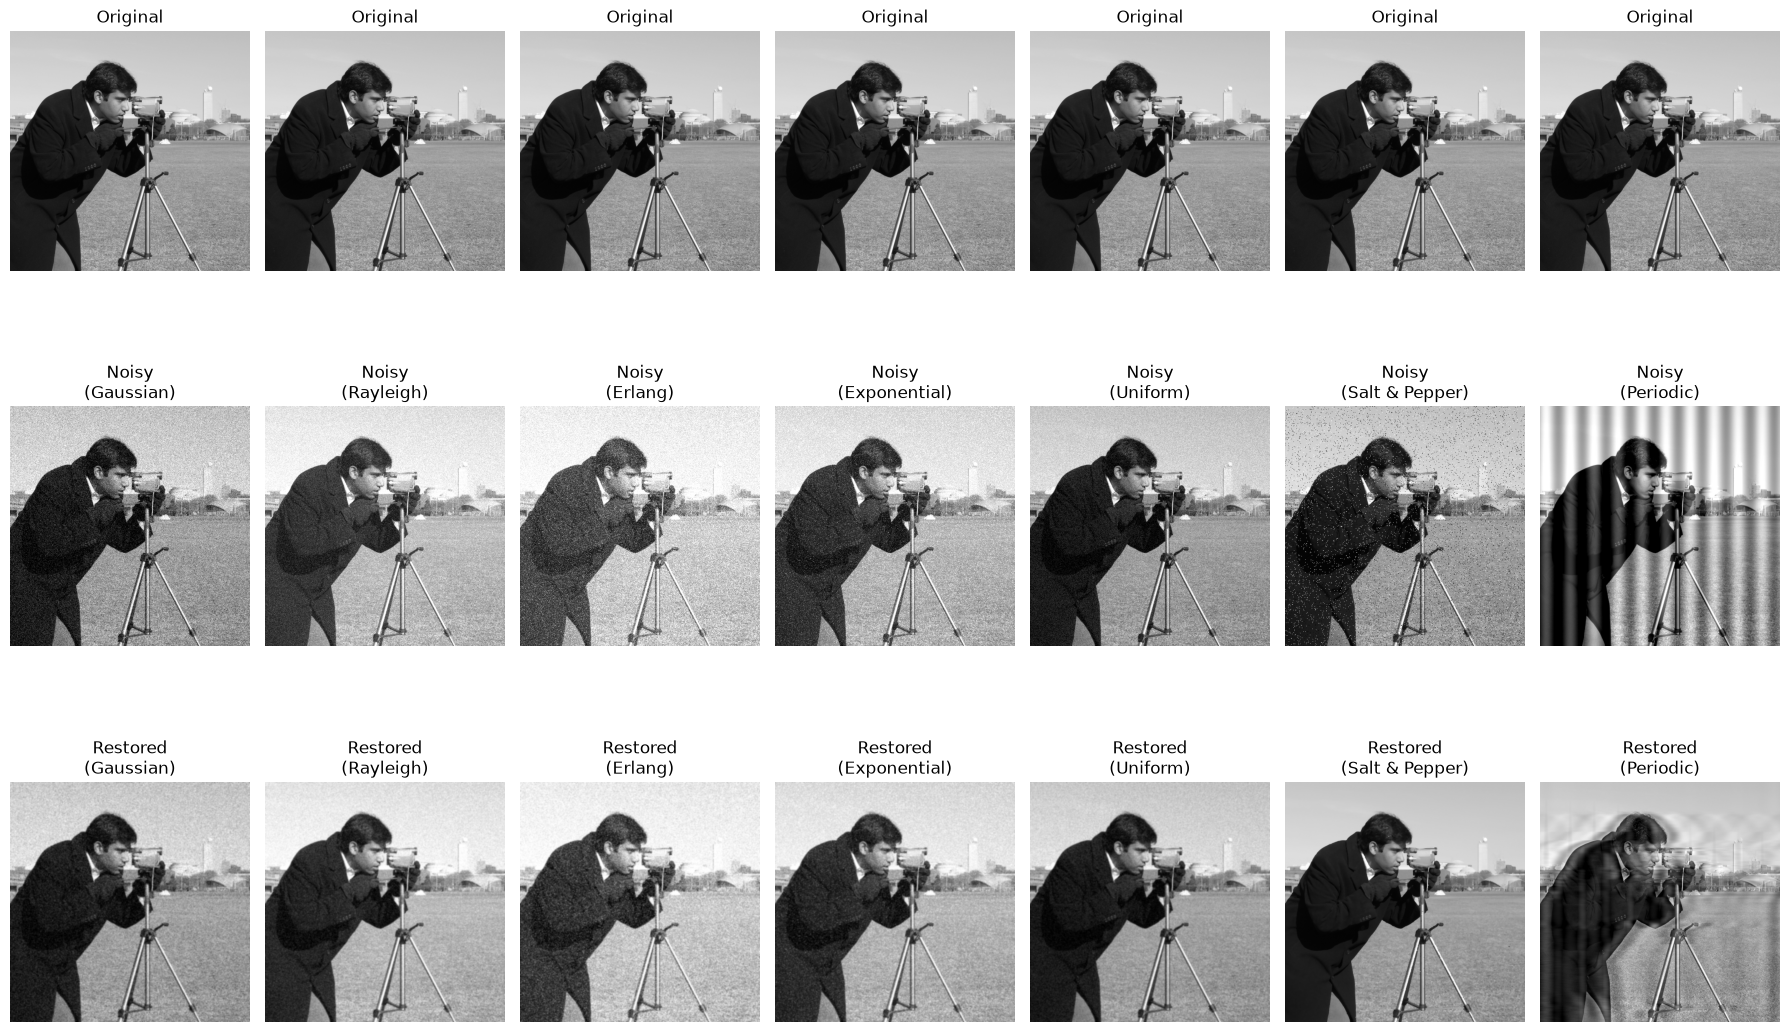

In [2]:
# Load image
image = img_as_float(data.camera())

# Noise functions (same as before)
def add_gaussian_noise(image, mean=0, var=0.01):
    return random_noise(image, mode='gaussian', mean=mean, var=var)

def add_rayleigh_noise(image, scale=0.1):
    noise = np.random.rayleigh(scale, image.shape)
    noisy_img = image + noise
    return np.clip(noisy_img, 0, 1)

def add_erlang_noise(image, shape=2, scale=0.1):
    noise = np.random.gamma(shape, scale, image.shape)
    noisy_img = image + noise
    return np.clip(noisy_img, 0, 1)

def add_exponential_noise(image, scale=0.1):
    noise = np.random.exponential(scale, image.shape)
    noisy_img = image + noise
    return np.clip(noisy_img, 0, 1)

def add_uniform_noise(image, low=-0.1, high=0.1):
    noise = np.random.uniform(low, high, image.shape)
    noisy_img = image + noise
    return np.clip(noisy_img, 0, 1)

def add_salt_and_pepper_noise(image, amount=0.05):
    return random_noise(image, mode='s&p', amount=amount)

def add_periodic_noise(image, amplitude=0.2, frequency=10):
    rows, cols = image.shape
    x = np.arange(cols)
    y = np.arange(rows)
    X, Y = np.meshgrid(x, y)
    sinusoid = amplitude * np.sin(2 * np.pi * frequency * X / cols)
    noisy_img = image + sinusoid
    return np.clip(noisy_img, 0, 1)


# Add noises
noisy_images = {
    'Gaussian': add_gaussian_noise(image),
    'Rayleigh': add_rayleigh_noise(image),
    'Erlang': add_erlang_noise(image),
    'Exponential': add_exponential_noise(image),
    'Uniform': add_uniform_noise(image),
    'Salt & Pepper': add_salt_and_pepper_noise(image),
    'Periodic': add_periodic_noise(image)
}

# Restoration functions
def restore_gaussian(noisy_img, sigma=1):
    return gaussian_filter(noisy_img, sigma=sigma)

def restore_median(noisy_img, size=3):
    return median_filter(noisy_img, size=size)

def restore_periodic(noisy_img, notch_freq=10, notch_width=5):
    # FFT of noisy image
    f = fft2(noisy_img)
    fshift = fftshift(f)
    rows, cols = noisy_img.shape

    # Create notch filter mask (block frequencies near notch_freq horizontally)
    mask = np.ones((rows, cols))
    center_row, center_col = rows // 2, cols // 2

    for i in range(rows):
        for j in range(cols):
            # Distance from horizontal notch frequency line
            if abs(j - center_col - notch_freq) < notch_width or abs(j - center_col + notch_freq) < notch_width:
                mask[i, j] = 0

    # Apply notch filter
    fshift_filtered = fshift * mask
    f_ishift = ifftshift(fshift_filtered)
    img_back = ifft2(f_ishift)
    img_back = np.real(img_back)
    img_back = np.clip(img_back, 0, 1)
    return img_back

# Apply restorations
restored_images = {}

for key, noisy_img in noisy_images.items():
    if key == 'Salt & Pepper':
        restored = restore_median(noisy_img, size=3)
    elif key == 'Periodic':
        restored = restore_periodic(noisy_img, notch_freq=10, notch_width=5)
    else:
        restored = restore_gaussian(noisy_img, sigma=1)
    restored_images[key] = restored

# Plot original, noisy and restored images side-by-side for comparison
plt.figure(figsize=(18, 12))

for i, key in enumerate(noisy_images.keys()):
    plt.subplot(3, len(noisy_images), i + 1)
    plt.imshow(image, cmap='gray')
    plt.title('Original')
    plt.axis('off')

    plt.subplot(3, len(noisy_images), i + 1 + len(noisy_images))
    plt.imshow(noisy_images[key], cmap='gray')
    plt.title(f'Noisy\n({key})')
    plt.axis('off')

    plt.subplot(3, len(noisy_images), i + 1 + 2 * len(noisy_images))
    plt.imshow(restored_images[key], cmap='gray')
    plt.title(f'Restored\n({key})')
    plt.axis('off')

plt.tight_layout()
plt.show()
